# 1. Dutch names generation

Language model implemented with RNN

In [115]:
# ! gdown 1QDbtPWGQypYxiS4pC_hHBBtbRHk9gEtr
# ! unzip name_dataset.zip

In [116]:
import pandas as pd
import numpy as np

df = pd.read_csv("name_dataset/data/NL.csv", header=None, dtype=pd.StringDtype()).dropna()
names_data = np.unique(df.loc[df[0].str.fullmatch("^[a-zA-Z]+$"), 0].to_numpy())

In [117]:
df 

,0,1,2,3
0,Patrick,De Kleijn,M,NL
1,Marco,Visser,M,NL
2,Remon,Griffioen,M,NL
3,Mercedes,Roa,F,NL
4,Odette,Schoonenberg,F,NL
...,...,...,...,...
5429153,Tineke,Waterreus,F,NL
5429154,Kensjero,Marcello,M,NL
5429155,Linde,Caris,F,NL
5429156,Dirk,Van Dijk,M,NL


In [118]:
np.random.choice(names_data, 10)

array(['Huissen', 'Hasbas', 'Brozius', 'Skndr', 'Infinity', 'Oeddek',
       'Daanz', 'Yuexiang', 'Suzeth', 'Ronold'], dtype=object)

In [119]:
len(names_data)

257736

## Dataset

**Processing pipeline:**

chars (tokens) $\to$ indices $\to$ embeddings $\to$ RNN output, hidden $\to$ next char logits

In [120]:
! pip install tokenizers

In [121]:
from tokenizers import ByteLevelBPETokenizer


def train_bpe_tokenizer(names,
                        vocab_size: int = 1000,
                        min_frequency: int = 2):
    """
    Обучаем BPE на списке имён.
    """
    tokenizer = ByteLevelBPETokenizer()
    tokenizer.train_from_iterator(
        names,
        vocab_size=vocab_size,
        min_frequency=min_frequency,
        special_tokens=["<pad>", "<bos>", "<eos>", "<unk>"],
    )
    return tokenizer

In [122]:
bpe_tokenizer = train_bpe_tokenizer(names_data, vocab_size=200, min_frequency=100)

In [123]:
import matplotlib.pyplot as plt
import seaborn as sns
# from tqdm.notebook import tqdm
from IPython.display import clear_output
from torch.utils.data import Dataset, DataLoader
import torch

class NamesDataset(Dataset):
    def __init__(self, names, bpe_tokenizer: ByteLevelBPETokenizer):
        self.names = names
        self.specials = ['<pad>', '<bos>', '<eos>']

        self.tokenizer = bpe_tokenizer

        self.pad_index = self.tokenizer.token_to_id('<pad>')
        self.bos_index = self.tokenizer.token_to_id('<bos>')
        self.eos_index = self.tokenizer.token_to_id('<eos>')

        self.max_len = max(len(self.encode(name)) for name in names)

    def __len__(self):
        return len(self.names)

    def str_to_idx(self, text: str):
        return self.tokenizer.encode(text).ids

    def idx_to_str(self, idx):
        if isinstance(idx, torch.Tensor):
            idx = idx.detach().cpu().tolist()
        return self.tokenizer.decode(idx)

    def encode(self, text: str):
        ids = self.tokenizer.encode(text).ids
        return [self.bos_index] + ids + [self.eos_index]

    def decode(self, idx):
        if isinstance(idx, torch.Tensor):
            idx = idx.detach().cpu().tolist()
        filtered = [
            i for i in idx
            if i not in (self.pad_index, self.bos_index, self.eos_index)
        ]
        return self.tokenizer.decode(filtered)

    def __getitem__(self, item):
        encoded = self.encode(self.names[item])
        padded = torch.full((self.max_len,), self.pad_index, dtype=torch.int64)
        padded[:len(encoded)] = torch.tensor(encoded, dtype=torch.int64)
        return padded, len(encoded)

In [124]:
dataset = NamesDataset(names_data, bpe_tokenizer)
dataloader = DataLoader(dataset, batch_size=512, shuffle=True)

In [125]:
for names, _ in dataloader:
    break

# 0 - <pad> - paddint token
# 1 - <bos> - beginning of a sequence
# 2 - <eos> - end of a sequence
names[:4]

tensor([[ 1, 48, 72, 85, 76, 72, 79,  2,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
          0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0],
        [ 1, 48, 72, 85, 74, 72,  2,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
          0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0],
        [ 1, 38, 79, 68, 92,  2,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
          0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0],
        [ 1, 39, 68, 76, 85, 92, 86, 68,  2,  0,  0,  0,  0,  0,  0,  0,  0,  0,
          0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0]])

## Generator model

Embedding + RNN + Linear head

In [126]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

In [127]:
dataset.tokenizer.get_vocab_size()

260

In [55]:
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.distributions.categorical import Categorical


class Generator(nn.Module):
    def __init__(self, dataset, embed_dim=32, hidden_dim=32, max_len=None):
        super().__init__()
        self.embedding = nn.Embedding(num_embeddings=dataset.tokenizer.get_vocab_size(), embedding_dim=embed_dim,
                                      padding_idx=dataset.pad_index)
        self.rnn = nn.RNN(input_size=embed_dim, hidden_size=hidden_dim, batch_first=True)
        self.linear = nn.Linear(hidden_dim, dataset.tokenizer.get_vocab_size())
        self.dataset = dataset
        self.max_len = dataset.max_len if max_len is None else max_len

    def forward(self, tokens, lengths):
        '''
        B - batch size
        L - sequence length
        E - embedding dim
        H - hidden dim
        V - vocab size
        '''
        # tokens: (B, L)
        embeds = self.embedding(tokens)
        # embeds: (B, L, E) in padded form
        packed_embeds = pack_padded_sequence(embeds, lengths, batch_first=True, enforce_sorted=False)
        outputs, hidden = self.rnn(packed_embeds)
        # output: (B, L, H), hidden: (B, H) in packed form
        outputs, lengths = pad_packed_sequence(outputs, batch_first=True)
        logits = self.linear(outputs)
        # logits: (B, L, V)
        return logits

    @torch.no_grad()
    def inference(self, prefix=''):
        # encode prefix
        tokens = self.dataset.encode(prefix)[:-1]
        tokens = torch.tensor(tokens).unsqueeze(0).to(device)

        # generate hidden for prefix
        embeds = self.embedding(tokens)
        output, hidden = self.rnn(embeds)
        logits = self.linear(output)

        # sample new token from logits
        new_tokens = Categorical(logits=logits[:, -1:]).sample()
        tokens = torch.cat([tokens, new_tokens], dim=1)

        # 2 stopping conditions: reaching max len or getting <eos> token
        while tokens.shape[1] < self.max_len:
            if new_tokens.item() == self.dataset.eos_index:
                break

            # process newly obtained token
            embeds = self.embedding(new_tokens)
            output, hidden = self.rnn(embeds, hidden)
            logits = self.linear(output)
            # sample the next token from logits
            new_tokens = Categorical(logits=logits[:, -1:]).sample()
            tokens = torch.cat([tokens, new_tokens], dim=1)

        # decode result to a string
        return self.dataset.decode(tokens.squeeze())

In [128]:
model = Generator(dataset, embed_dim=32, hidden_dim=32).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss(ignore_index=dataset.pad_index)

In [129]:
# inference for untrained model - trash
[model.inference('') for _ in range(10)]

['��[A5�\x1e�k�#z�\x0f"�+�\x0f5���\x1a��\x1e�b�',
 'Y�p:��W��z�\x1c ���\x1f\x11\x0efK���\x18�6��3�',
 '\\P�~Ќ�\x1fS\x05bU�n�|�\x16+��I�1!Ĭ�\x1a�',
 '���2.o�kӑ��\x11\x08糿yD�\x02f��W�2�\x00q�',
 '\x08\x05\x0eY\r(�\x12Q�2{\x17^�\nN�pb}Q��\x07��5',
 '\x1a�.=�\x1c�7�;(\x04�\x17��K��"�r�\x11O�����E',
 "���'�;@�A\x1c\x19#7\x0e5�h\x05&��p����_.\x04�",
 "'ڷ)2��2��֟�:\r�\x02\x15��e�ы*�UN\x08",
 "�\t�\x05DT\x0c�w� J8\x1e__'\x17�yeyZ�S�5K\x00�\x0f",
 '\x18�\x11��KځO�]�#�\x0c�>�\x12\x14o�\x0fk\r�0\x1e�q']

## Training

In [130]:
def plot_losses(losses):
    clear_output()
    plt.plot(range(1, len(losses) + 1), losses)
    plt.xlabel('epoch')
    plt.ylabel('loss')
    plt.show()

In [131]:
from tqdm import trange

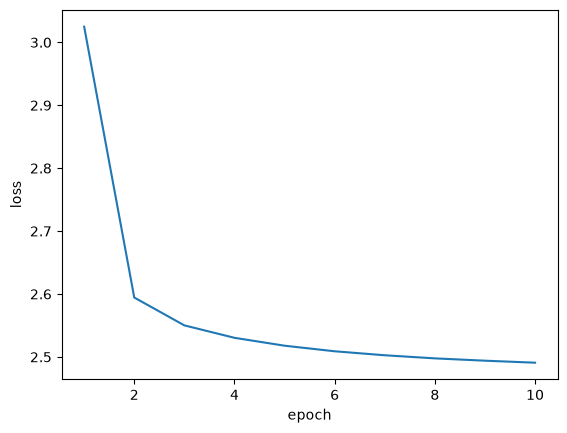

100%|██████████| 10/10 [02:30<00:00, 15.09s/it]


In [60]:
losses = []
num_epochs = 10

for epoch in trange(1, num_epochs + 1):
    running_loss = 0.0
    model.train()
    for tokens, lengths in dataloader:
        optimizer.zero_grad()
        tokens = tokens[:, :lengths.max()].to(device)
        logits = model(tokens[:, :-1], lengths - 1)
        # logits: (B, L, V), tokens: (B, L) - need to transpose logits
        loss = criterion(logits.transpose(1, 2), tokens[:, 1:])
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * tokens.shape[0]
    
    losses += [running_loss / len(dataset)]
    
    if epoch % 10 == 0:
        plot_losses(losses)

In [61]:
# unconditional generation
[model.inference('') for _ in range(10)]

['Anhliode',
 'Kahmot',
 'Snerling',
 'Paurien',
 'Raynvolou',
 'Sancaly',
 'Marlain',
 'Fldo',
 'Nitm',
 'Leoneeda']

In [62]:
# conditional generation from prefix
[model.inference('Van') for _ in range(10)]

['Vangen',
 'Vanier',
 'Vandanz',
 'Vanyokk',
 'Vandh',
 'Vanellee',
 'Vanoun',
 'Vanse',
 'Vantht',
 'Vanoyman']

# 2. Image captioning

In [64]:
%pip install -q -U kaggle
!kaggle datasets download -d hsankesara/flickr-image-dataset -p . --unzip

Note: you may need to restart the kernel to use updated packages.
Dataset URL: https://www.kaggle.com/datasets/hsankesara/flickr-image-dataset
License(s): CC0-1.0
100%|█████████████████████████████████████| 8.16G/8.16G [04:27<00:00, 32.8MB/s]



In [132]:
import os
import pandas as pd
from PIL import Image

In [133]:
captions = pd.read_csv('flickr30k_images/results.csv', sep='\|\ ').dropna()
captions

/tmp/ipykernel_17077/311428869.py:1: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support separators > 1 char, including regex separators; you can avoid this warning by specifying engine='python'.
  captions = pd.read_csv('flickr30k_images/results.csv', sep='\|\ ').dropna()
Exception ignored in: <function tqdm.__del__ at 0x7f1925ca7b00>
Traceback (most recent call last):
  File "/home/iasudakov/.conda/envs/cnf/lib/python3.11/site-packages/tqdm/std.py", line 1154, in __del__
    self.close()
  File "/home/iasudakov/.conda/envs/cnf/lib/python3.11/site-packages/tqdm/notebook.py", line 279, in close
    self.disp(bar_style='danger', check_delay=False)
    ^^^^^^^^^
AttributeError: 'tqdm_notebook' object has no attribute 'disp'


,image_name,comment_number,comment
0,1000092795.jpg,0,Two young guys with shaggy hair look at their ...
1,1000092795.jpg,1,"Two young , White males are outside near many ..."
2,1000092795.jpg,2,Two men in green shirts are standing in a yard .
3,1000092795.jpg,3,A man in a blue shirt standing in a garden .
4,1000092795.jpg,4,Two friends enjoy time spent together .
...,...,...,...
158910,998845445.jpg,0,A man in shorts and a Hawaiian shirt leans ove...
158911,998845445.jpg,1,"A young man hanging over the side of a boat , ..."
158912,998845445.jpg,2,A man is leaning off of the side of a blue and...
158913,998845445.jpg,3,"A man riding a small boat in a harbor , with f..."


1: A foreign store and hotel with streets that look run down with a kid in a bicycle sitting .
2: A little boy and his bike sit outside the Kuthhoop Hotel .
3: A boy waiting outside the kitchen holding his bike .
4: a small child with a bike outside of a shop
5: A boy is sitting by a bike , by a hotel .


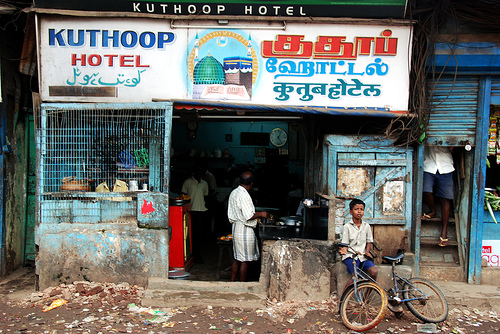

In [134]:
image_file = captions.image_name.sample(1).iloc[0]
for i, caption in enumerate(captions[captions.image_name == image_file].comment):
    print(f'{i + 1}:', caption)
Image.open(os.path.join('flickr30k_images/flickr30k_images', image_file))

In [135]:
image_ids = {k: i for i, k in enumerate(captions.image_name.unique())}
image_list = list(map(lambda x: x[0], sorted(image_ids.items(), key=lambda x: x[1])))
captions['image_id'] = captions.image_name.map(image_ids)

In [136]:
from torch.utils.data import Dataset, DataLoader

class ImagesDataset(Dataset):
    def __init__(self, root, image_list, transform=None):
        super().__init__()
        self.root = root
        self.image_list = image_list
        self.transform = transform

    def __len__(self):
        return len(self.image_list)

    def __getitem__(self, item):
        image_path = os.path.join(self.root, self.image_list[item])
        image = Image.open(image_path).convert('RGB')

        if self.transform is not None:
            image = self.transform(image)

        return image

In [137]:
import torch

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

In [138]:
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights
from torch import nn

cnn_model = mobilenet_v2(weights=MobileNet_V2_Weights.IMAGENET1K_V1).eval().to(device)
cnn_model.classifier = nn.Identity()

In [139]:
import torchvision.transforms as T

transform = T.Compose([
    T.ToTensor(),
    T.Resize(256),
    T.CenterCrop(224),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

dataset = ImagesDataset(root='flickr30k_images/flickr30k_images', image_list=image_list, transform=transform)
dataloader = DataLoader(dataset, num_workers=4, shuffle=False, batch_size=128)

In [140]:
from tqdm.auto import tqdm

image_embeds = []

with torch.no_grad():
    for images in tqdm(dataloader, total=len(dataloader)):
        embeds = cnn_model(images.to(device))
        image_embeds += [embeds.cpu()]

image_embeds = torch.cat(image_embeds, dim=0)

100%|██████████| 249/249 [00:48<00:00,  5.08it/s]


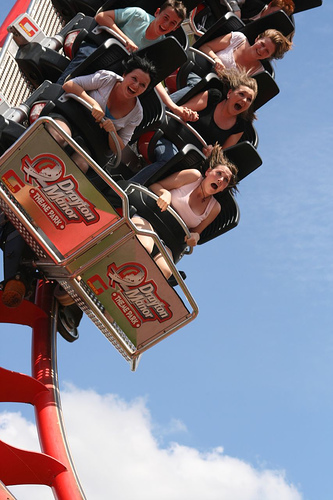

In [141]:
i = 1001
image = Image.open(f'flickr30k_images/flickr30k_images/{image_list[i]}').convert('RGB')
image

In [142]:
captions[captions.image_id == 1001]

,image_name,comment_number,comment,image_id
5005,1315116409.jpg,0,A Drayton Manor Theme Park roller coaster is s...,1001
5006,1315116409.jpg,1,The Drayton Manor Theme Park roller coaster on...,1001
5007,1315116409.jpg,2,While everybody else is having fun on a roller...,1001
5008,1315116409.jpg,3,Several people are riding on a roller coaster ...,1001
5009,1315116409.jpg,4,Family of people right before they crash to th...,1001


In [143]:
image_embeds[i]

tensor([1.5271, 1.4365, 0.1388,  ..., 0.7424, 0.2805, 0.5695])

In [144]:
cnn_model(transform(image).to(device).unsqueeze(0))

tensor([[1.5271, 1.4365, 0.1388,  ..., 0.7424, 0.2805, 0.5695]],
       device='cuda:0', grad_fn=<ViewBackward0>)

In [145]:
from sklearn.model_selection import train_test_split

train_images, test_images, train_embeds, test_embeds = \
    train_test_split(image_list, image_embeds, test_size=0.25, random_state=42)

train_embeds.shape, test_embeds.shape

(torch.Size([23837, 1280]), torch.Size([7946, 1280]))

In [146]:
import torchvision.transforms as T

transform = T.Compose([
    T.ToTensor(),
    T.Resize(256),
    T.CenterCrop(224),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

dataset = ImagesDataset(root='flickr30k_images/flickr30k_images', image_list=image_list, transform=transform)
dataloader = DataLoader(dataset, num_workers=4, shuffle=False, batch_size=128)

In [147]:
train_captions = captions[captions.image_name.isin(train_images)]
test_captions = captions[captions.image_name.isin(test_images)]

train_captions.shape, test_captions.shape

((119184, 4), (39730, 4))

In [150]:
test_captions

,image_name,comment_number,comment,image_id
30,1000919630.jpg,0,A man sits in a chair while holding a large st...,6
31,1000919630.jpg,1,A man is sitting on a chair holding a large st...,6
32,1000919630.jpg,2,A man completes the finishing touches on a stu...,6
33,1000919630.jpg,3,A man holds a large stuffed lion toy .,6
34,1000919630.jpg,4,A man is smiling at a stuffed lion,6
...,...,...,...,...
158900,997876722.jpg,0,Two male construction workers are working on a...,31780
158901,997876722.jpg,1,Two workmen with a wheelbarrow for mixing ceme...,31780
158902,997876722.jpg,2,Men in orange and yellow clothing lean over a ...,31780
158903,997876722.jpg,3,Men are working on pouring concrete outside of...,31780


In [151]:
from nltk.tokenize import WordPunctTokenizer
from itertools import chain
from typing import Iterable, Union, Optional
from collections import Counter
import torch

tokenizer = WordPunctTokenizer()

class VocabPseudoVectorized:
    def __init__(self, train_data: Iterable[str],
                 unk_label: str = "<unk>",
                 bos_label: str = "<bos>",
                 eos_label: str = "<eos>",
                 pad_label: str = "<pad>",
                 unk_cutoff: int = 20):
        raw_counts = Counter(train_data)
        for token, frequency in tuple(raw_counts.items()):
            if frequency >= unk_cutoff:
                continue
            raw_counts.pop(token)
        remaining_tokens = list(raw_counts.keys())
        # add special tokens:
        remaining_tokens[0:0] = [pad_label, bos_label, eos_label, unk_label]

        self._token2idx = {
            token: id_ for id_, token in enumerate(remaining_tokens)
        }
        self._idx2token = {
            id_: token for id_, token in enumerate(remaining_tokens)
        }

    def _fetch_index(self, item: str):
        return self._token2idx.get(item, 0)

    def __getitem__(self, item: Union[str, Iterable[str]]) -> Union[int, list[int]]:
        if isinstance(item, Iterable) and not isinstance(item, str):
            return list(map(self.__getitem__, item))
    
        return self._fetch_index(item)

    def __call__(self, item: Union[str, Iterable[str]]) -> Union[int, list[int]]:
        return self[item]

    def __len__(self, ):
        return len(self._token2idx)

    def __contains__(self, item):
        return item in self._token2idx

    def lookup(self, item: Union[str, Iterable[str]]):
        result = []
        if isinstance(item, str):
            return self[item]
        for x in item:
            result.append(self.lookup(x))
        return result

    def get_itos(self, items: Optional[Iterable[str]]=None):
        if items is None:
            return self._idx2token
        if isinstance(items, torch.Tensor):
            items = items.detach().cpu().tolist()
        return [self._idx2token[i] for i in items]

In [152]:
train_captions['tokens'] = train_captions.comment.apply(tokenizer.tokenize)
test_captions['tokens'] = test_captions.comment.apply(tokenizer.tokenize)

In [153]:
train_captions['tokens']

0         [Two, young, guys, with, shaggy, hair, look, a...
1         [Two, young, ,, White, males, are, outside, ne...
2         [Two, men, in, green, shirts, are, standing, i...
3         [A, man, in, a, blue, shirt, standing, in, a, ...
4           [Two, friends, enjoy, time, spent, together, .]
                                ...                        
158910    [A, man, in, shorts, and, a, Hawaiian, shirt, ...
158911    [A, young, man, hanging, over, the, side, of, ...
158912    [A, man, is, leaning, off, of, the, side, of, ...
158913    [A, man, riding, a, small, boat, in, a, harbor...
158914    [A, man, on, a, moored, blue, and, white, boat...
Name: tokens, Length: 119184, dtype: object

In [158]:
list(chain.from_iterable(train_captions.tokens)), len(list(chain.from_iterable(train_captions.tokens)))

(['Two',
  'young',
  'guys',
  'with',
  'shaggy',
  'hair',
  'look',
  'at',
  'their',
  'hands',
  'while',
  'hanging',
  'out',
  'in',
  'the',
  'yard',
  '.',
  'Two',
  'young',
  ',',
  'White',
  'males',
  'are',
  'outside',
  'near',
  'many',
  'bushes',
  '.',
  'Two',
  'men',
  'in',
  'green',
  'shirts',
  'are',
  'standing',
  'in',
  'a',
  'yard',
  '.',
  'A',
  'man',
  'in',
  'a',
  'blue',
  'shirt',
  'standing',
  'in',
  'a',
  'garden',
  '.',
  'Two',
  'friends',
  'enjoy',
  'time',
  'spent',
  'together',
  '.',
  'Several',
  'men',
  'in',
  'hard',
  'hats',
  'are',
  'operating',
  'a',
  'giant',
  'pulley',
  'system',
  '.',
  'Workers',
  'look',
  'down',
  'from',
  'up',
  'above',
  'on',
  'a',
  'piece',
  'of',
  'equipment',
  '.',
  'Two',
  'men',
  'working',
  'on',
  'a',
  'machine',
  'wearing',
  'hard',
  'hats',
  '.',
  'Four',
  'men',
  'on',
  'top',
  'of',
  'a',
  'tall',
  'structure',
  '.',
  'Three',
  'men',

In [154]:
vocab = VocabPseudoVectorized(chain.from_iterable(train_captions.tokens))
itos = vocab._idx2token

PAD_IDX, BOS_IDX, EOS_IDX, UNK_IDX = vocab['<pad>'], vocab['<bos>'], vocab['<eos>'], vocab['<unk>']
VOCAB_SIZE = len(vocab)
VOCAB_SIZE

3235

In [159]:
train_captions

,image_name,comment_number,comment,image_id,tokens
0,1000092795.jpg,0,Two young guys with shaggy hair look at their ...,0,"[Two, young, guys, with, shaggy, hair, look, a..."
1,1000092795.jpg,1,"Two young , White males are outside near many ...",0,"[Two, young, ,, White, males, are, outside, ne..."
2,1000092795.jpg,2,Two men in green shirts are standing in a yard .,0,"[Two, men, in, green, shirts, are, standing, i..."
3,1000092795.jpg,3,A man in a blue shirt standing in a garden .,0,"[A, man, in, a, blue, shirt, standing, in, a, ..."
4,1000092795.jpg,4,Two friends enjoy time spent together .,0,"[Two, friends, enjoy, time, spent, together, .]"
...,...,...,...,...,...
158910,998845445.jpg,0,A man in shorts and a Hawaiian shirt leans ove...,31782,"[A, man, in, shorts, and, a, Hawaiian, shirt, ..."
158911,998845445.jpg,1,"A young man hanging over the side of a boat , ...",31782,"[A, young, man, hanging, over, the, side, of, ..."
158912,998845445.jpg,2,A man is leaning off of the side of a blue and...,31782,"[A, man, is, leaning, off, of, the, side, of, ..."
158913,998845445.jpg,3,"A man riding a small boat in a harbor , with f...",31782,"[A, man, riding, a, small, boat, in, a, harbor..."


In [160]:
MAX_LENGTH = 40

class CaptionsDataset(Dataset):
    def __init__(self, tokens, embeds):
        super().__init__()
        self.tokens = tokens
        self.embeds = embeds

    def __len__(self):
        return len(self.tokens)

    def tokens_to_idx(self, tokens):
        return [vocab[token] for token in tokens]
    
    def idx_to_tokens(self, idx):
        return [itos[index.item()] for index in idx]

    def encode(self, tokens):
        tokens = ['<bos>'] + tokens + ['<eos>']
        return self.tokens_to_idx(tokens)

    def decode(self, idx):
        tokens = self.idx_to_tokens(idx)
        return ' '.join(token for token in tokens if token not in ['<pad>', '<bos>', '<eos>', '<unk>'])

    def __getitem__(self, item):
        tokens = self.tokens.iloc[item].tokens
        encoded = self.encode(tokens)[:MAX_LENGTH + 2]
        padded = torch.full((MAX_LENGTH + 2, ), PAD_IDX, dtype=torch.int64)
        padded[:len(encoded)] = torch.tensor(encoded)

        image_id = self.tokens.iloc[item].image_id
        return padded, len(encoded), self.embeds[image_id]

In [161]:
train_set = CaptionsDataset(train_captions, image_embeds)
test_set = CaptionsDataset(test_captions, image_embeds)

train_loader = DataLoader(train_set, batch_size=128, shuffle=True, num_workers=4, pin_memory=True)
test_loader = DataLoader(test_set, batch_size=128, shuffle=False, num_workers=4, pin_memory=True)
embeds_loader = DataLoader(test_embeds, batch_size=128, shuffle=False, num_workers=4, pin_memory=True)

In [162]:
captions_list = []

for image in tqdm(test_images):
    data = test_captions[test_captions.image_name == image]
    captions_list += [data.comment.str.lower().tolist()]

100%|██████████| 7946/7946 [00:45<00:00, 174.01it/s]


In [163]:
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.distributions.categorical import Categorical
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights


class CaptionRNN(nn.Module):
    def __init__(self, image_embed_dim, embed_dim=256, hidden_dim=256, lstm_layers=1, dropout=0.1):
        super().__init__()
        self.lstm_layers = lstm_layers
        self.hidden_dim = hidden_dim

        self.image_embed_to_h0 = nn.Sequential(
            nn.Linear(image_embed_dim, lstm_layers * hidden_dim),
            nn.LeakyReLU(0.1),
        )
        self.image_embed_to_c0 = nn.Sequential(
            nn.Linear(image_embed_dim, lstm_layers * hidden_dim),
            nn.LeakyReLU(0.1),
        )

        self.embedding = nn.Embedding(num_embeddings=VOCAB_SIZE, embedding_dim=embed_dim,
                                      padding_idx=PAD_IDX)
        self.lstm = nn.LSTM(input_size=embed_dim, hidden_size=hidden_dim,
                            num_layers=lstm_layers, batch_first=True)
        self.linear = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, VOCAB_SIZE)
        )

    def forward(self, tokens, lengths, image_embeds):
        '''
        B - batch size
        M - lstm layers
        L - sequence length
        I - image embedding dim
        E - embedding dim
        H - hidden dim
        V - vocab size
        '''
        # image_embeds: (B, I)
        B = image_embeds.shape[0]
        h0 = self.image_embed_to_h0(image_embeds).reshape(B, self.lstm_layers, self.hidden_dim).transpose(0, 1)
        c0 = self.image_embed_to_c0(image_embeds).reshape(B, self.lstm_layers, self.hidden_dim).transpose(0, 1)
        # h0, co: (M, B, H)

        # tokens: (B, L)
        embeds = self.embedding(tokens)
        # embeds: (B, L, E) in padded form

        packed_embeds = pack_padded_sequence(embeds, lengths, batch_first=True, enforce_sorted=False)
        outputs, (h, c) = self.lstm(packed_embeds, (h0, c0))
        # output: (B, L, H) in packed form, (h, c): (M, B, H)
        outputs, lengths = pad_packed_sequence(outputs, batch_first=True)
        logits = self.linear(outputs)
        # logits: (B, L, V)
        return logits

    @torch.no_grad()
    def inference(self, image_embeds):
        self.eval()
        # generate lstm input
        B = image_embeds.shape[0]
        h = self.image_embed_to_h0(image_embeds).reshape(B, self.lstm_layers, self.hidden_dim).transpose(0, 1)
        c = self.image_embed_to_c0(image_embeds).reshape(B, self.lstm_layers, self.hidden_dim).transpose(0, 1)
        h, c = h.contiguous(), c.contiguous()

        # init tokens with <bos>
        tokens = torch.full((B, 1), BOS_IDX, device=image_embeds.device)
        new_tokens = tokens

        # 2 stopping conditions: reaching max len or getting <eos> token
        while tokens.shape[1] < MAX_LENGTH:
            if ((tokens == EOS_IDX).sum(1) > 0).all():
                break

            # process newly obtained token
            embeds = self.embedding(new_tokens)
            output, (h, c) = self.lstm(embeds, (h, c))
            logits = self.linear(output)

            # get new tokens from logits
            new_tokens = logits.argmax(dim=-1)
            tokens = torch.cat([tokens, new_tokens], dim=1)

        return tokens

In [164]:
# testing
model = CaptionRNN(image_embeds.shape[1])

for tokens, lengths, embeds in train_loader:
    break

tokens = tokens[:, :lengths.max()]
logits = model(tokens, lengths, embeds)
assert logits.shape == (tokens.shape[0], tokens.shape[1], VOCAB_SIZE)

tokens = model.inference(embeds)
train_set.decode(tokens[0])

'deck onlookers joy bearded peering lane pulled station orchestra suspenders firefighter barrel balloons I pyramid passes clay brick fabric gold clothed smaller bandanna take rooftop discussion fallen loom loom loom loom loom summer washing loom loom loom loom loom'

In [165]:
from IPython.display import clear_output
# from tqdm.notebook import tqdm
import numpy as np


BLEU_FREQ = 5


def plot_losses(train_losses, test_losses, test_blues):
    clear_output()
    fig, axs = plt.subplots(1, 2, figsize=(13, 4))
    axs[0].plot(range(1, len(train_losses) + 1), train_losses, label='train', color='deepskyblue', linewidth=2)
    axs[0].plot(range(1, len(test_losses) + 1), test_losses, label='test', color='springgreen', linewidth=2)
    axs[0].set_ylabel('loss')

    axs[1].plot(BLEU_FREQ * np.arange(1, len(test_blues) + 1), test_blues, label='test',
                color='springgreen', linewidth=2)
    axs[1].set_ylabel('BLEU')

    for ax in axs:
        ax.set_xlabel('epoch')
        ax.legend()

    plt.show()

In [166]:
from torchmetrics import BLEUScore
from tqdm import tqdm

def training_epoch(model, optimizer, criterion, train_loader, tqdm_desc):
    train_loss = 0.0
    model.train()
    for tokens, lengths, embeds in tqdm(train_loader, desc=tqdm_desc):
        embeds = embeds.to(device)
        tokens = tokens[:, :lengths.max()].to(device)

        optimizer.zero_grad()
        logits = model(tokens[:, :-1], lengths - 1, embeds)
        loss = criterion(logits.transpose(1, 2), tokens[:, 1:])
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * embeds.shape[0]

    train_loss /= len(train_loader.dataset)
    return train_loss


@torch.no_grad()
def validation_epoch(model, criterion, valid_loader, tqdm_desc):
    valid_loss = 0.0
    model.eval()
    for tokens, lengths, embeds in tqdm(valid_loader, desc=tqdm_desc):
        embeds = embeds.to(device)
        tokens = tokens[:, :lengths.max()].to(device)

        logits = model(tokens[:, :-1], lengths - 1, embeds)
        loss = criterion(logits.transpose(1, 2), tokens[:, 1:])

        valid_loss += loss.item() * embeds.shape[0]

    valid_loss /= len(valid_loader.dataset)
    return valid_loss


def evaluate_bleu(model, embeds_loader, captions):
    bleu = BLEUScore()
    predictions = []
    model.eval()
    for embeds in tqdm(embeds_loader, desc='Evaluating BLEU'):
        tokens = model.inference(embeds.to(device)).cpu()
        for token_list in tokens:
            predictions += [train_set.decode(token_list)]
    
    return bleu(predictions, captions).item()


def train(model, optimizer, scheduler, criterion, train_loader, valid_loader,
          embeds_loader, captions_list, num_epochs):
    train_losses, valid_losses, valid_blues = [], [], []

    for epoch in range(1, num_epochs + 1):
        train_loss = training_epoch(
            model, optimizer, criterion, train_loader,
            tqdm_desc=f'Training {epoch}/{num_epochs}'
        )
        valid_loss = validation_epoch(
            model, criterion, valid_loader,
            tqdm_desc=f'Validating {epoch}/{num_epochs}'
        )

        if epoch % BLEU_FREQ == 0:
            valid_bleu = evaluate_bleu(model, embeds_loader, captions_list)
            valid_blues += [valid_bleu]

        if scheduler is not None:
            scheduler.step()

        train_losses += [train_loss]
        valid_losses += [valid_loss]
        plot_losses(train_losses, valid_losses, valid_blues)

In [167]:
NUM_EPOCHS = 20

model = CaptionRNN(image_embeds.shape[1], dropout=0.3).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-6)
scheduler = None
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)

sum(param.numel() for param in model.parameters())

2841763

In [169]:
print(f'Random BLEU: {evaluate_bleu(model, embeds_loader, captions_list):.4f}')

Evaluating BLEU: 100%|██████████| 63/63 [00:02<00:00, 23.94it/s]


Random BLEU: 0.0000


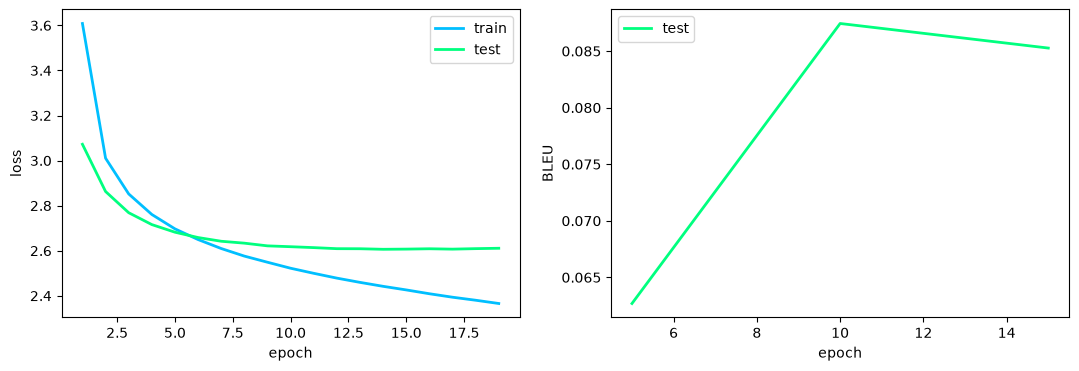

Training 20/20:   8%|▊         | 73/932 [00:01<00:13, 61.39it/s]


KeyboardInterrupt: 

In [114]:
train(model, optimizer, scheduler, criterion, train_loader, test_loader,
      embeds_loader, captions_list, NUM_EPOCHS)

In [56]:
def caption_random_test_image():
    index = np.random.randint(len(test_images))
    image_file = test_images[index]
    tokens = model.inference(test_embeds[index].unsqueeze(0).to(device)).cpu().squeeze()
    prediction = train_set.decode(tokens)
    print('Prediction:', prediction)

    for i, caption in enumerate(captions[captions.image_name == image_file].comment):
        print(f'GT caption #{i + 1}:', caption)

    return Image.open(os.path.join('flickr30k_images/flickr30k_images', image_file)).convert('RGB')

Prediction: A group of people are standing in a body of water .
GT caption #1: A group of girls walking and talking along the beach with a building in the background .
GT caption #2: women on the beach returning to their car after long day
GT caption #3: Five women walk along a beach wearing flip-flops .
GT caption #4: A group of women walking away from a beach .
GT caption #5: Young women coming home from the beach .


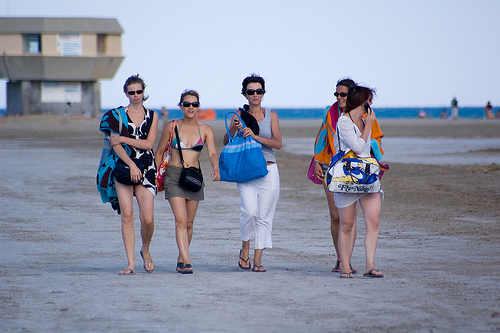

In [57]:
caption_random_test_image()

Prediction: A man in a blue shirt and jeans is walking down a sidewalk .
GT caption #1: A cleaning lady walks down the road with a sweeping machine what looks to be an entry way of a building .
GT caption #2: A woman pushes a cleaning machine while walking on a brick pathway beside a minivan yellow cab .
GT caption #3: A woman pushing a piece of cleaning equipment , while walking in front of a cab .
GT caption #4: A woman wearing a white shirt walks on the sidewalk with a large sweeper .
GT caption #5: Person in white shirt standing outside with a buffer machine .


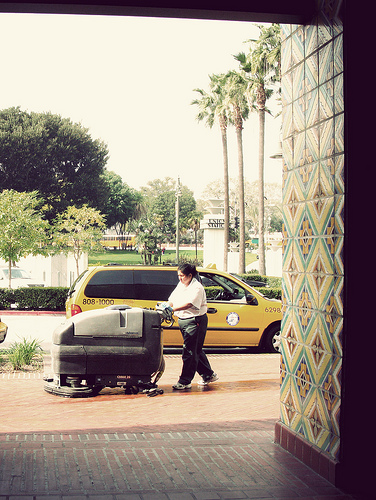

In [58]:
caption_random_test_image()

Prediction: A woman in a black shirt and jeans is sitting on a bench .
GT caption #1: A man with dark glasses , a black jacket , and a white and red horizontally-striped shirt pointing at something while standing on a sidewalk .
GT caption #2: A man in sunglasses , a red striped sweater , and a leather jacket smiles and points his finger .
GT caption #3: A man in a leather jacket and striped shirt points at something off-camera .
GT caption #4: A man with shaggy hair and a moustache pointing down a street .
GT caption #5: The man with the red and gray shirt and glasses is pointing .


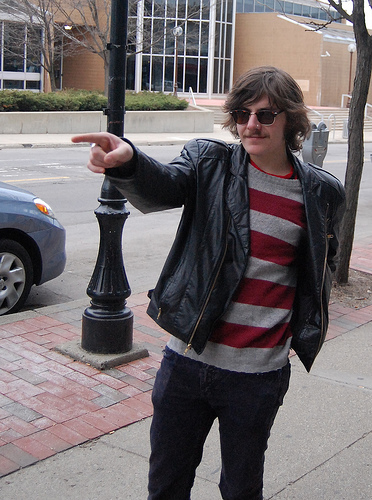

In [59]:
caption_random_test_image()

Prediction: A young boy is playing with a toy gun .
GT caption #1: A young boy with a white shirt is holding two large ripe green organic food items .
GT caption #2: A boy in a gray t-shirt , brown hair , holding two large cucumbers .
GT caption #3: A young boy in a gray shirt holds onto two over-sized cucumbers .
GT caption #4: A boy in a gray shirt holding two over-sized cucumbers .
GT caption #5: A boy carrying two green vegetables .


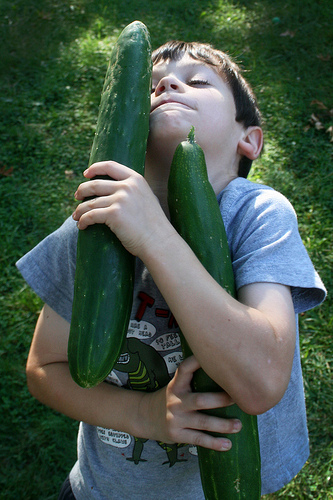

In [60]:
caption_random_test_image()

# 3. Code reproducibility

In [29]:
import torch
import numpy as np
import random
import os
from torch import nn

def set_random_seed(seed):
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8' # or :16:8

In [30]:
set_random_seed(0xDEADF00D)

In [31]:
a = nn.Conv2d(1, 1, kernel_size=3, bias=True).to("cuda:2")
a.weight, a.bias

(Parameter containing:
 tensor([[[[-0.2808, -0.1553,  0.2176],
           [ 0.1008,  0.0012, -0.1642],
           [-0.0923, -0.2754,  0.3187]]]], device='cuda:2', requires_grad=True),
 Parameter containing:
 tensor([0.2705], device='cuda:2', requires_grad=True))

In [32]:
x = torch.randn(1, 1, 5, 5).to("cuda:2")
x

tensor([[[[-0.4343,  1.8815,  0.1638,  1.3481, -0.4343],
          [ 0.1004, -0.4767, -0.0350,  2.4472,  2.7177],
          [ 2.8190, -0.1433, -0.3422, -0.1957,  0.0862],
          [-1.5015,  1.1933,  0.6985, -0.4518,  0.6744],
          [-1.0870, -1.9972,  0.7447,  0.6049,  2.6260]]]], device='cuda:2')

In [33]:
a(x)

tensor([[[[-0.1785, -0.3950, -0.4133],
          [ 0.6813,  0.5130,  0.7175],
          [ 0.0497,  0.6885,  0.9763]]]], device='cuda:2',
       grad_fn=<ConvolutionBackward0>)

In [34]:
from torch.utils.data import DataLoader
dataloader = DataLoader(torch.arange(20), shuffle=True, num_workers=4, batch_size=3)
for batch in dataloader:
    print(batch)

tensor([5, 4, 8])
tensor([17,  7,  0])
tensor([ 1, 10, 15])
tensor([ 6,  3, 12])
tensor([ 2, 11, 14])
tensor([18, 13, 16])
tensor([ 9, 19])


In [35]:
set_random_seed(0xDEADF00D)

In [ ]:
a = nn.Conv2d(1, 1, kernel_size=3, bias=True).to("cuda:2")
a.weight, a.bias

(Parameter containing:
 tensor([[[[-0.2808, -0.1553,  0.2176],
           [ 0.1008,  0.0012, -0.1642],
           [-0.0923, -0.2754,  0.3187]]]], device='cuda:2', requires_grad=True),
 Parameter containing:
 tensor([0.2705], device='cuda:2', requires_grad=True))

In [37]:
x = torch.randn(1, 1, 5, 5).to("cuda:2")
x

tensor([[[[-0.4343,  1.8815,  0.1638,  1.3481, -0.4343],
          [ 0.1004, -0.4767, -0.0350,  2.4472,  2.7177],
          [ 2.8190, -0.1433, -0.3422, -0.1957,  0.0862],
          [-1.5015,  1.1933,  0.6985, -0.4518,  0.6744],
          [-1.0870, -1.9972,  0.7447,  0.6049,  2.6260]]]], device='cuda:2')

In [38]:
a(x)

tensor([[[[-0.1785, -0.3950, -0.4133],
          [ 0.6813,  0.5130,  0.7175],
          [ 0.0497,  0.6885,  0.9763]]]], device='cuda:2',
       grad_fn=<ConvolutionBackward0>)

In [39]:
dataloader = DataLoader(torch.arange(20), shuffle=True, num_workers=4, batch_size=3)
for batch in dataloader:
    print(batch)

tensor([5, 4, 8])
tensor([17,  7,  0])
tensor([ 1, 10, 15])
tensor([ 6,  3, 12])
tensor([ 2, 11, 14])
tensor([18, 13, 16])
tensor([ 9, 19])
